# The transversal CCZ, level by level: Eqs. (6.45) and (6.46) of L. Yeh's thesis

> **In short.**
> * **What this is.** L. Yeh's thesis (Section 6.5, "Diagonal gates") proves that $T$ on four qubits of the [[8,3,2]] code and $T^\dagger$ on the other four is a logical CCZ. It writes the logical gate as $L = E; P; E^\dagger$ (the encoder, the layer $P$ of $T$ and $T^\dagger$ gates, the decoder) and rewrites it in Eq. (6.45): with the encoder as a circuit, the CNOTs on either side of $P$ are moved through it one group at a time, and each $T$ becomes a *phase gadget* on the parity the CNOTs computed. Eq. (6.46) then removes the gadgets that involve the encoder's random bit $w$ (the spider-nest identity), leaving the CCZ of Eq. (6.44). Here the circuit of $L$ is levelled up, one level per step, and the levels give these diagrams.
> * **Levels and rewrites.** Each level-up takes a block of the circuit and applies one rewrite to it (`level_up(..., rewrite=...)`); the level's picture is the whole circuit with that block rewritten (`reduced_level`). Two rewrites (`zxqec.gpf.rules.phase_gadgets`): `'phase gadgets'`, the block reduced to normal form with each $T$ on a phase gadget and drawn along the wires; `'spider nest'`, the same with the gadgets simplified as a whole (the spider-nest identities).
> * **The levels.** 0: the circuit (the second diagram of Eq. (6.45)). 1: `'phase gadgets'` on the CNOTs from z, $P$ and their inverses (the third). 2: the same with the CNOTs from y (the fourth). 3: from x (the fifth). 4: the GHZ state and its inverse, so the whole circuit (the sixth: eight gadgets on x, y, z and $w$). 5: `'spider nest'` (Eq. (6.46): seven gadgets on x, y and z, the CCZ). The first diagram of Eq. (6.45), with the encoder in parity normal form, is the tool's own composite for question 2.
> * **The check.** Every level's picture is compared with the circuit, as linear maps (`equal_for_all_assignments`), and the last with PyZX's CCZ gate.
> * **How to read the pictures.** Lines are qubits, time runs left to right; green and red dots are Z- and X-spiders. A phase gadget is a red dot joined to several green ones, with a green leaf carrying its phase. A phase $7\pi/4$ is $-\pi/4$.
> * The program on the code itself, and the tool's own reduction: [TransversalCCZ.ipynb](TransversalCCZ.ipynb).

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, '..')
import pyzx as zx
from pyzx.circuit import Circuit
from pyzx.circuit.gates import CCZ, CNOT, T, PostSelect
from zxqec.qprogram import QProgram
from zxqec.gpf import equal_for_all_assignments
from zxqec.spacetime import draw_program, view_levels

# qubit k here is the thesis's qubit THESIS[k] (Eq. (6.27)); x, y and z enter on qubits 1, 2 and 3
THESIS = [8, 7, 6, 4, 1, 2, 3, 5]
# the wires, as the thesis draws them, top to bottom: its qubits 7, 6, 4, 1, 2, 3, 5, 8
WIRES = {1: 0, 2: 1, 3: 2, 4: 3, 5: 4, 6: 5, 7: 6, 0: 7}
# the encoder of Eq. (6.27): a GHZ state on the thesis's qubits 8, 1, 2, 3, 5, then four CNOTs from each of x, y, z
GHZ = [CNOT(0, 4), CNOT(0, 5), CNOT(0, 6), CNOT(0, 7)]
FROM_X = [CNOT(1, 4), CNOT(1, 6), CNOT(1, 7), CNOT(0, 1)]
FROM_Y = [CNOT(2, 4), CNOT(2, 5), CNOT(2, 7), CNOT(0, 2)]
FROM_Z = [CNOT(3, 4), CNOT(3, 5), CNOT(3, 6), CNOT(0, 3)]
# P of Eq. (6.45): T on the thesis's qubits 1, 4, 6, 7, T^dag on 2, 3, 5, 8
P = [T(1), T(2), T(3), T(4), T(5, adjoint=True), T(6, adjoint=True), T(7, adjoint=True), T(0, adjoint=True)]

## The circuit of $L = E; P; E^\dagger$

Nine stages: the encoder of Eq. (6.27) (the GHZ state, the CNOTs from x, from y and from z), $P$, and the decoder $E^\dagger$: the same CNOTs in the opposite order, then the GHZ qubits projected back onto the states they started in (`PostSelect`: $\langle +|$ on qubit 0, $\langle 0|$ on qubits 4 to 7). The qubits are numbered so that the tool's own logical operators of the code are those of x, y and z (see [TransversalCCZ.ipynb](TransversalCCZ.ipynb)); the wires are drawn in the thesis's order.

deterministic: every run implements CCZ


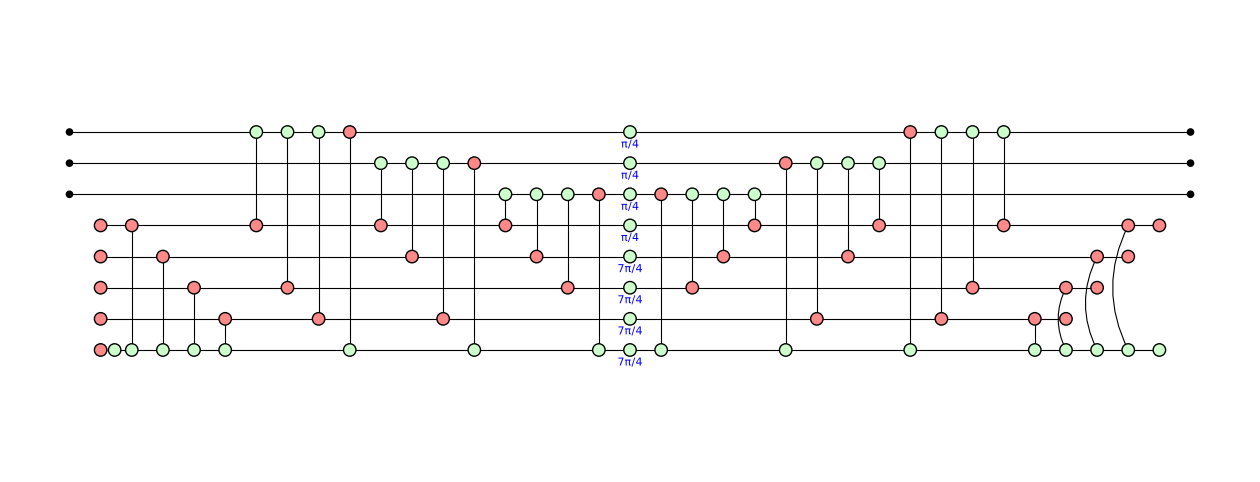

In [2]:
circuit = QProgram(8, mapping=WIRES, initial_states={0: '+', 4: '0', 5: '0', 6: '0', 7: '0'})
decode = GHZ[::-1] + [PostSelect(0, '+')] + [PostSelect(q, '0') for q in (4, 5, 6, 7)]
for gates, name in ((GHZ, 'GHZ'), (FROM_X, 'from x'), (FROM_Y, 'from y'), (FROM_Z, 'from z'), (P, 'P'),
                    (FROM_Z[::-1], 'to z'), (FROM_Y[::-1], 'to y'), (FROM_X[::-1], 'to x'), (decode, 'GHZ back')):
    c = Circuit(8)
    for gate in gates:
        c.add_gate(gate)
    circuit.add_circuit(c, name=name)
print(circuit.logical_action().verdict())
draw_program(circuit, show_time=False, labels=False, figsize=(16, 6))

Grouped into the encoder, $P$ and the decoder, the tool answers questions 2 and 3: the identity, CCZ, the identity. For $P$ it builds the composite of the code's ideal encoder (in parity normal form: a Z-spider for each of x, y, z and $w$, an X-spider for each qubit), $P$ and the ideal decoder: the first diagram of Eq. (6.45).

block       role              code before                        code after                         logical action  every run?  checks
0 E         encoder           [[1,1,1]] + [[1,1,1]] + [[1,1,1]]  [[8,3,2]]                          I               yes         ok
1 P         transversal gate  [[8,3,2]]                          [[8,3,2]]                          CCZ             yes         ok
2 E dagger  decoder           [[8,3,2]]                          [[1,1,1]] + [[1,1,1]] + [[1,1,1]]  I               yes         ok


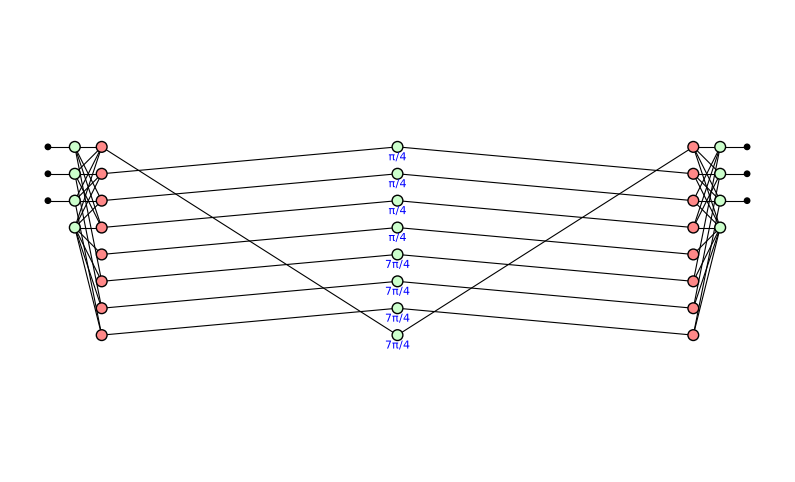

In [3]:
parts = circuit.group_stages([(0, 3, 'E', 'encoder'), (4, 4, 'P', 'transversal gate'), (5, 8, 'E dagger', 'decoder')])
print(str(circuit.summary(parts)).split('\n\n')[0])
zx.draw_matplotlib(circuit.logical_action(parts, 1).composite, figsize=(10, 6))

## The levels

Levels form a chain: levelling up again from the circuit (level 0) starts a new chain, which replaces the grouping above. Each line below is one level-up: the blocks it groups and the rewrite it applies.

In [4]:
through_z = circuit.level_up(0, 3, 5, 'z', rewrite='phase gadgets')
through_y = circuit.level_up(through_z, 2, 4, 'y', rewrite='phase gadgets')
through_x = circuit.level_up(through_y, 1, 3, 'x', rewrite='phase gadgets')
through_ghz = circuit.level_up(through_x, 0, 2, 'all', rewrite='phase gadgets')
nest = circuit.level_up(through_ghz, 0, 0, 'all', rewrite='spider nest')
for level in (through_z, through_y, through_x, through_ghz, nest):
    print(circuit.describe_level(level), end='\n\n')

Level 1 (7 blocks):
  Block 0 'GHZ': [GHZ]
  Block 1 'from x': [from x]
  Block 2 'from y': [from y]
  Block 3 'z' <rewrite: phase gadgets>: [from z, P, to z]
  Block 4 'to y': [to y]
  Block 5 'to x': [to x]
  Block 6 'GHZ back': [GHZ back]

Level 2 (5 blocks):
  Block 0 'GHZ': [GHZ]
  Block 1 'from x': [from x]
  Block 2 'y' <rewrite: phase gadgets>: [from y, from z, P, to z, to y]
  Block 3 'to x': [to x]
  Block 4 'GHZ back': [GHZ back]

Level 3 (3 blocks):
  Block 0 'GHZ': [GHZ]
  Block 1 'x' <rewrite: phase gadgets>: [from x, from y, from z, P, to z, to y, to x]
  Block 2 'GHZ back': [GHZ back]

Level 4 (1 blocks):
  Block 0 'all' <rewrite: phase gadgets>: [GHZ, from x, from y, from z, P, to z, to y, to x, GHZ back]

Level 5 (1 blocks):
  Block 0 'all' <rewrite: spider nest>: [GHZ, from x, from y, from z, P, to z, to y, to x, GHZ back]



## Level 0: the circuit (the second diagram)

The thesis draws the GHZ state as one Z-spider joined to five wires; the program prepares it with $|+\rangle$, four $|0\rangle$ and four CNOTs, and undoes it the same way.

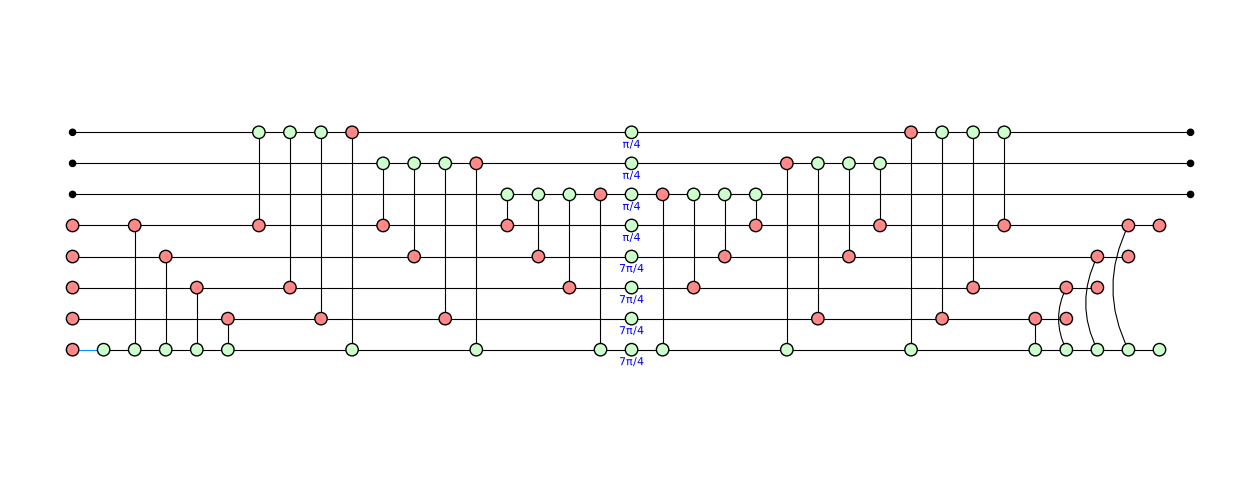

In [5]:
circuit_graph = circuit.quantum_graph()
zx.draw_matplotlib(circuit_graph, figsize=(16, 6))

## Level 1: through the CNOTs from z (the third diagram)

`'phase gadgets'` on the CNOTs from z, $P$, and their inverses. The CNOTs cancel with their inverses; each $T$ on a wire that a CNOT changed becomes a gadget on that wire and the wire the CNOT came from (z, or for z's own wire, the bottom wire); the other $T$ stay as phases on their wires.

z (3 children): 24 spiders -> 16 after rewrite phase gadgets
the same map as the circuit: True


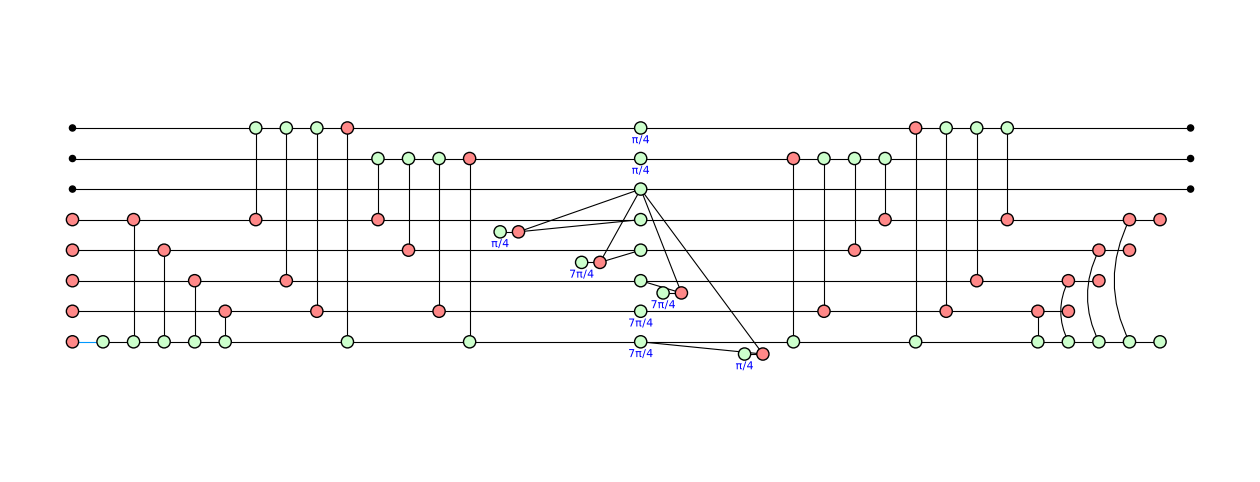

In [6]:
print(circuit.reduced_block(through_z, 3))
level = circuit.reduced_level(through_z)
print("the same map as the circuit:", equal_for_all_assignments(circuit_graph, level.graph))
zx.draw_matplotlib(level.graph, figsize=(16, 6))

## Level 2: through the CNOTs from y (the fourth diagram)

`'phase gadgets'` on the CNOTs from y, the block of level 1, and their inverses: the CNOTs from y cancel and the gadgets reach the wire of y.

y (3 children): 32 spiders -> 20 after rewrite phase gadgets
the same map as the circuit: True


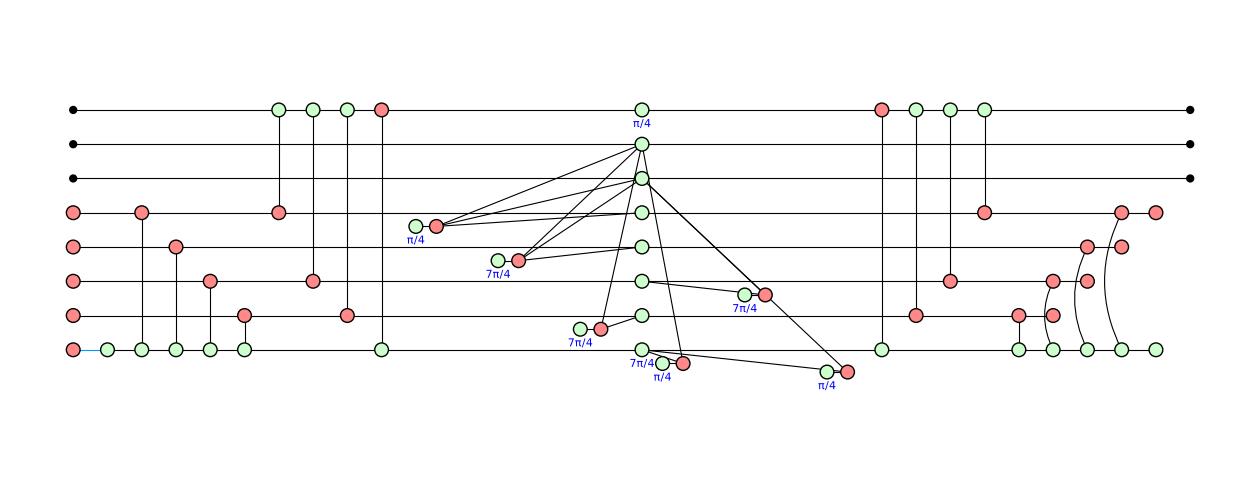

In [7]:
print(circuit.reduced_block(through_y, 2))
level = circuit.reduced_level(through_y)
print("the same map as the circuit:", equal_for_all_assignments(circuit_graph, level.graph))
zx.draw_matplotlib(level.graph, figsize=(16, 6))

## Level 3: through the CNOTs from x (the fifth diagram)

The same with the CNOTs from x. Only the GHZ state and its inverse are left around the gadgets.

x (3 children): 36 spiders -> 22 after rewrite phase gadgets


the same map as the circuit: True


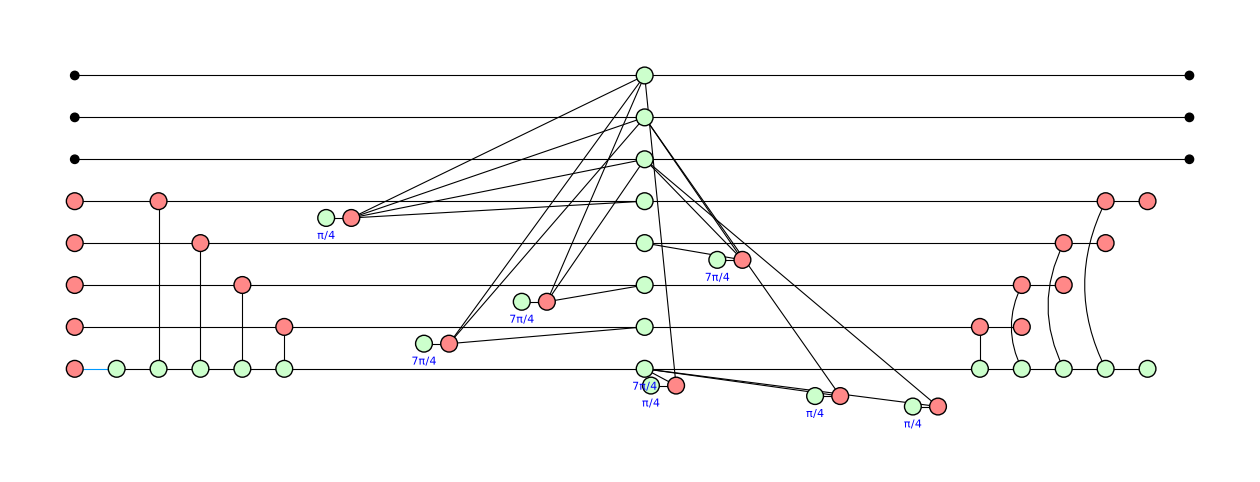

In [8]:
print(circuit.reduced_block(through_x, 1))
level = circuit.reduced_level(through_x)
print("the same map as the circuit:", equal_for_all_assignments(circuit_graph, level.graph))
zx.draw_matplotlib(level.graph, figsize=(16, 6))

## Level 4: through the GHZ state (the sixth diagram)

`'phase gadgets'` on the whole circuit. The GHZ state and its inverse become one Z-spider inside the diagram, $w$ (drawn below the wires), and every $T$ a gadget on a parity of x, y, z and $w$: the corner of its qubit, plus $w$. Eight gadgets (the one on $w$ alone drawn as the phase of $w$'s spider): the last diagram of Eq. (6.45).

all (3 children): 49 spiders -> 18 after rewrite phase gadgets


the same map as the circuit: True


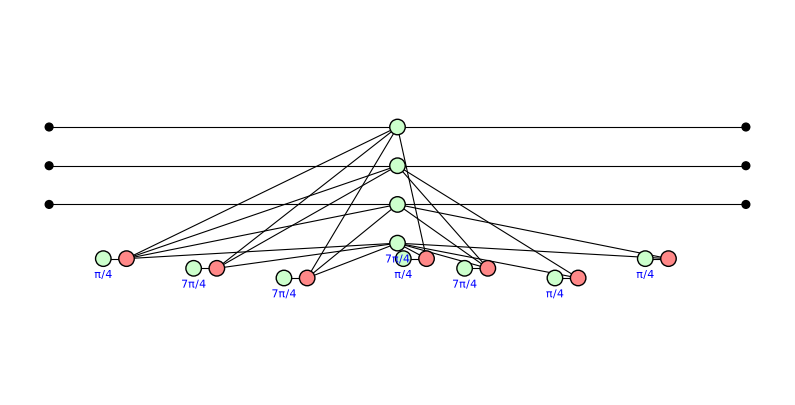

In [9]:
print(circuit.reduced_block(through_ghz, 0))
level = circuit.reduced_level(through_ghz)
print("the same map as the circuit:", equal_for_all_assignments(circuit_graph, level.graph))
zx.draw_matplotlib(level.graph, figsize=(10, 5))

## Level 5: the spider nest (Eq. (6.46))

`'spider nest'` on the whole circuit: the gadgets are simplified as a whole (`simplify_gadgets`), which writes their phases as one polynomial. Every term with $w$ cancels, which is the spider-nest identity the thesis applies in Eq. (6.46) (all the gadgets on 0 to 4 of x, y, z, $w$ with alternating signs are the identity), and $w$ drops out. What remains is the right-hand side of Eq. (6.44): $\pi/4$ on each of x, y and z, $-\pi/4$ on each pair, $\pi/4$ on all three, the CCZ.

all (1 children): 18 spiders -> 11 after rewrite spider nest
the same map as the circuit: True
the same map as PyZX's CCZ gate: True


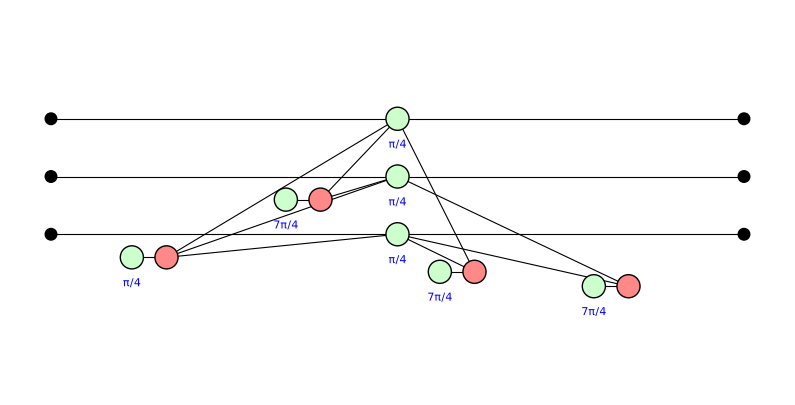

In [10]:
print(circuit.reduced_block(nest, 0))
level = circuit.reduced_level(nest)
print("the same map as the circuit:", equal_for_all_assignments(circuit_graph, level.graph))
ccz = Circuit(3)
ccz.add_gate(CCZ(0, 1, 2))
print("the same map as PyZX's CCZ gate:", equal_for_all_assignments(level.graph, ccz.to_graph()))
zx.draw_matplotlib(level.graph, figsize=(10, 5))

## The levels window

`view_levels` shows a level: its blocks outlined in the circuit (those they were made from dashed), the circuit as the level rewrites it, and the selected block; with an interactive backend the slider moves through the levels. Here, level 2.

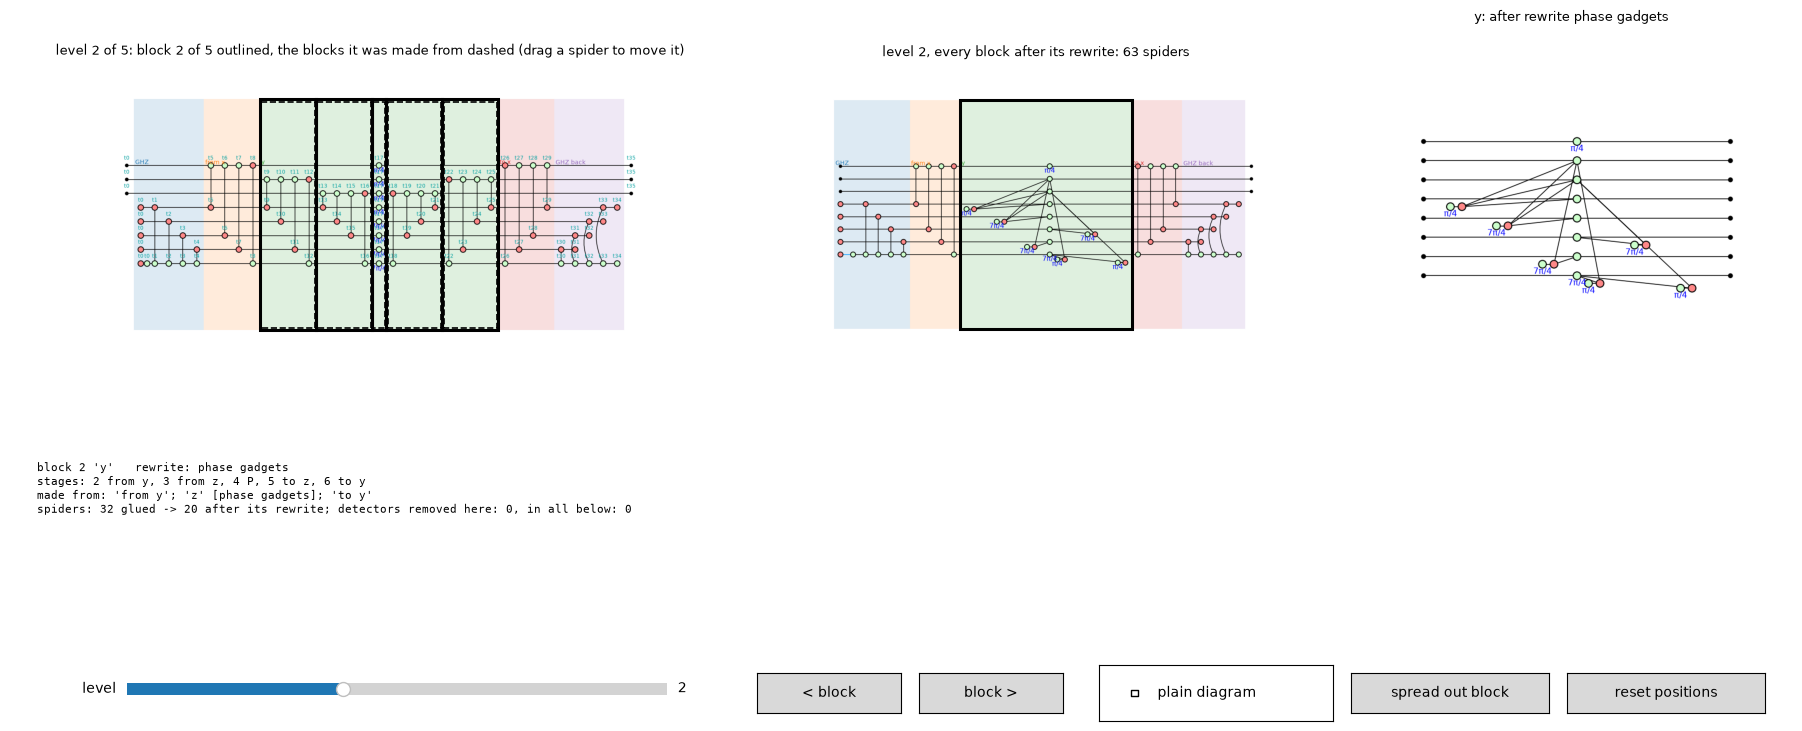

In [11]:
window = view_levels(circuit, through_y, 2)

## How this differs from the figure

* The thesis draws the GHZ state and its inverse as one Z-spider each; here they are $|+\rangle$, four $|0\rangle$ and four CNOTs, and $\langle +|$, four $\langle 0|$ and four CNOTs.
* The thesis's first diagram ($E$ in parity normal form) is the tool's composite for $P$, not a level: levels form one chain, from the circuit.
* The pictures are PyZX's drawings, with each gadget placed by the rewrite just below the lowest wire it touches; the thesis places them by hand. A gadget on one wire is drawn as a phase on that wire, as in the thesis.
* Eq. (6.46) goes through two pictures with boxes ("all 0-4 legged minus all 0-3 legged nests", "remaining 0-3 legged nests"); level 5 goes from the eight gadgets to the seven in one step.

What is not covered: the blocks and their order are chosen to follow the figure; the tool checks each level against the circuit but does not choose them.